# Named Entity Recognition: Data Efficiency and Error Analysis

**Joe Williams · Completed Colab experiment · November 17, 2026**

**Question:** How do 10%, 25%, and 100% of the available training sentences affect BERT's entity extraction, training time, and errors?

**Main result:** mean validation entity F1 was **0.4679**, **0.8241**, and **0.9312** for the three fractions across three seeds. The selected full-data, seed-42 checkpoint achieved **0.9030 test entity F1**.

This notebook includes all 16 original code cells, their execution counts, and saved numerical outputs from the completed Colab run. Those outputs match the supplied result archive `ner_20261117T193146Z-d76812.zip`. Result summaries and interpretation were added after execution. Colab-only progress/download widgets were removed for GitHub display; the training code and numerical results are unchanged.

The NER baseline is adapted from *Hands-On Large Language Models* (Jay Alammar and Maarten Grootendorst, 2024), Chapter 11. Original code copyright 2024 Jay Alammar & Maarten Grootendorst; Apache-2.0. [Chapter source](https://github.com/HandsOnLLM/Hands-On-Large-Language-Models/tree/main/chapter11). The portfolio adds nested data-size comparisons, three seeds, strict entity scoring, timing, saved predictions, and error analysis.

### Inspect or reproduce

- **Read the saved results without running cells.** The training and final-test switches remain enabled in this executed record.
- To run a new experiment, make a separate notebook copy, choose a T4 GPU in Colab, and use Runtime → Run all. This trains nine models and evaluates one selected checkpoint on the test split, creating a separate result directory.
- Download both the new result ZIP and the notebook with its executed outputs when finished.

The result ZIP excludes large model checkpoints and raw corpus text. Temporary runtime files disappear when the Colab runtime is removed.


## Recorded results

The completed Colab experiment used a Tesla T4. All nine validation runs and the selected model's test result were recalculated from the supplied word-level predictions and probabilities.

| Training fraction | Sentences | Mean entity F1 ± SD | Mean precision | Mean recall | Mean training time ± SD |
| --- | ---: | ---: | ---: | ---: | ---: |
| 10% | 1,404 | 0.4679 ± 0.0644 | 0.4586 | 0.4782 | 15.60 ± 0.39 s |
| 25% | 3,510 | 0.8241 ± 0.0096 | 0.8261 | 0.8221 | 37.68 ± 0.28 s |
| 100% | 14,041 | 0.9312 ± 0.0005 | 0.9327 | 0.9297 | 152.11 ± 3.89 s |

Each row summarizes seeds 42, 43, and 44 on the same 3,250 validation sentences. SD is the sample standard deviation across those runs; it is not a confidence interval. Timing covers the synchronized training call, excluding loading, validation, and saving.

The full-data fraction had the highest mean validation F1 and was selected. Its prespecified seed-42 checkpoint achieved **0.9030 test entity F1**, precision **0.9024**, and recall **0.9037** on **3,453 sentences**. This is one checkpoint's test result, not a three-seed test average.

The test set contains 5,648 reference entities. The model produced 5,656 entities: **5,104 matched exactly**, **552 were unmatched predictions**, and **544 reference entities were missed**. An incorrect type or boundary can contribute both an unmatched prediction and a missed reference; these counts are not numbers of incorrect sentences.

## What the comparison shows

Increasing the training fraction from 10% to 25% raised mean validation F1 by **0.3561**. Moving from 25% to 100% added **0.1071 F1**, while increasing mean training-call time from **37.68 to 152.11 seconds**—about **4.04 times as long**. All three seeds improved at each increase in training fraction.

The 25% run provides an observed lower-time option at lower entity F1. Full-data training is the best performer under the declared highest-F1 rule. The experiment does not identify a universally optimal cost/performance point or show that more data always produces these gains.

Variation across seeds was much larger at 10% than at 100%: F1 ranged from **0.4217 to 0.5415** at 10%, compared with **0.9307 to 0.9315** at 100%. The seed changes both the sample and the training process for smaller fractions, so these sources of variation are not separately estimated.

The selected checkpoint's validation F1 was **0.9315**, compared with **0.9030** on test, a difference of **0.0285**. The difference alone does not identify its cause or prove overfitting.

## Test performance by entity type

| Type | Reference entities | Precision | Recall | F1 |
| --- | ---: | ---: | ---: | ---: |
| PER | 1,617 | 0.9569 | 0.9604 | 0.9586 |
| LOC | 1,668 | 0.9252 | 0.9197 | 0.9224 |
| ORG | 1,661 | 0.8956 | 0.8784 | 0.8869 |
| MISC | 702 | 0.7480 | 0.7949 | 0.7707 |

PER (people) had the highest test F1; MISC (miscellaneous entities) had the lowest. Those descriptive scores depend on the benchmark's labeling rules and support counts. They are not results for every kind of person, place, organization, or miscellaneous entity in other domains.


## 1. Install the experiment dependencies

Core training and scoring packages use fixed versions. Colab's existing GPU-compatible PyTorch is retained. The actual Python, library, and hardware versions are saved with the results. The notebook uses `seqeval` directly, so evaluation does not download executable metric code.


In [1]:
# Install compatible, fixed versions of the main experiment packages.
%pip install -q --use-pep517 "transformers==4.57.6" "datasets==4.4.1" "accelerate==1.12.0" "seqeval==1.2.2" "huggingface-hub>=0.34,<1" "numpy>=1.26,<3" "pandas>=2.2,<3" "matplotlib>=3.8,<4" "scikit-learn>=1.5,<2"


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.10.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Imports and fixed settings

Each fraction uses three seeds: **42, 43, and 44**. Within a seed, the 10% sample is contained in the 25% sample, which is contained in the full sample. Models restart from the same pretrained checkpoint; no training continues from an earlier fraction.

All runs use one epoch, batch size 16, learning rate 0.00002, and weight decay 0.01. A larger dataset therefore also gives more optimizer updates. This compares **data plus its one-epoch training budget**, not a pure data effect at equal compute. Three seeds provide a small descriptive view of variation, not a confidence interval or a full robustness study.

The fraction with the highest **mean validation entity F1** is selected; exact ties favor less training data. Its **seed-42 checkpoint** is evaluated once on the test split. Seed 42 is fixed in advance, rather than chosen for a favorable validation result.


In [2]:
# Standard-library tools handle files, timestamps, timing, and cleanup.
import gc, hashlib, importlib.metadata, json, math, platform, shutil, time, uuid
from datetime import datetime, timezone
from pathlib import Path
# Numerical, plotting, table, and model libraries support the experiment.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForTokenClassification,
                          DataCollatorForTokenClassification, TrainingArguments, Trainer, set_seed)

# Immutable model and dataset snapshots were resolved when this notebook was prepared.
MODEL_ID = "google-bert/bert-base-cased"
MODEL_REVISION = "cd5ef92a9fb2f889e972770a36d4ed042daf221e"
DATASET_ID = "lhoestq/conll2003"
DATASET_REVISION = "19edcb426bfd625c275c17b9a99b2239243f4377"
# Compare these fixed training fractions using these fixed seeds.
FRACTIONS = [0.10, 0.25, 1.00]
SEEDS = [42, 43, 44]
TEST_SEED = SEEDS[0]
EPOCHS = 1
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
MAX_LENGTH = 512
# Run all performs the experiment directly; turn these off only for code inspection.
RUN_TRAINING = True
RUN_FINAL_TEST = True
# A GPU is required by default because full BERT training on a CPU is slow.
ALLOW_CPU_TRAINING = False
# Review text is displayed only when a specific validation row is chosen later.
SHOW_REVIEW_TEXT = False
REVIEW_ROW_ID = None


## 3. Correct entity evaluation

An entity counts as correct only when **its type and complete word span match** the reference. For example, predicting only “New” when the reference is “New York” produces one false positive and one false negative.

**Precision** = correct predicted entities / predicted entities. **Recall** = correct predicted entities / reference entities. **F1** balances precision and recall. Scores are micro-averaged over entities, with separate counts for PER, ORG, LOC, and MISC. Word accuracy is secondary because many words have the non-entity label `O`.

The code preserves sentence boundaries, scores each original word once, and uses strict BIO2. `B-PER` begins a person span; `I-PER` continues it. An invalid `I` transition is not silently repaired. Each calculated score is checked against `seqeval` in strict IOB2 mode. If no entities exist for a type, its score is reported as zero alongside its zero support.


In [3]:
import hashlib
import json
from pathlib import Path
import numpy as np
from seqeval.metrics import f1_score, precision_score, recall_score
from seqeval.scheme import IOB2


In [4]:
def write_json(path, value):
    """Write readable JSON and reject undefined/infinite numeric results."""
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

def strict_spans(tags):
    """Return (type, first_word, exclusive_end) entities under strict BIO2.

    B starts an entity. I extends only an existing entity of the same type.
    An orphan I does not create an entity. This preserves invalid transitions
    as errors instead of silently repairing the model's predictions.
    """
    spans = set()
    current_type, start = None, None
    for position, tag in enumerate(list(tags) + ["O"]):
        if tag == "O":
            prefix, entity_type = "O", None
        else:
            prefix, entity_type = tag.split("-", 1)
            if prefix not in {"B", "I"} or not entity_type:
                raise ValueError(f"Expected a BIO2 tag; received {tag!r}")
        # A matching I continues the open span; every other tag closes it.
        if current_type is not None and not (prefix == "I" and entity_type == current_type):
            spans.add((current_type, start, position))
            current_type, start = None, None
        if prefix == "B":
            current_type, start = entity_type, position
    return spans

def score_sequences(gold, predicted, entity_types):
    """Compute exact-span micro scores, per-type counts and word accuracy."""
    if len(gold) != len(predicted) or any(len(a) != len(b) for a, b in zip(gold, predicted)):
        raise ValueError("Gold and predicted sequences must align word for word.")
    if not gold or sum(map(len, gold)) == 0:
        raise ValueError("Evaluation needs at least one scored word.")
    counts = {t: {"tp": 0, "fp": 0, "fn": 0} for t in entity_types}
    correct_words = 0
    invalid_transitions = 0
    for reference, hypothesis in zip(gold, predicted):
        expected, actual = strict_spans(reference), strict_spans(hypothesis)
        for entity_type, _, _ in expected | actual:
            if entity_type not in counts:
                raise ValueError(f"Unknown entity type: {entity_type}")
        for t, _, _ in expected & actual:
            counts[t]["tp"] += 1
        for t, _, _ in actual - expected:
            counts[t]["fp"] += 1
        for t, _, _ in expected - actual:
            counts[t]["fn"] += 1
        correct_words += sum(a == b for a, b in zip(reference, hypothesis))
        previous = "O"
        for tag in hypothesis:
            if tag.startswith("I-") and previous not in {"B-" + tag[2:], tag}:
                invalid_transitions += 1
            previous = tag
    def summarize(c):
        tp, fp, fn = c["tp"], c["fp"], c["fn"]
        return {**c, "gold_entities": tp + fn, "predicted_entities": tp + fp,
                "precision": tp / (tp + fp) if tp + fp else 0.0,
                "recall": tp / (tp + fn) if tp + fn else 0.0,
                "f1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0}
    total = {k: sum(v[k] for v in counts.values()) for k in ("tp", "fp", "fn")}
    result = summarize(total)
    # Cross-check our transparent count calculations against the standard library.
    for name, function in (("precision", precision_score), ("recall", recall_score), ("f1", f1_score)):
        reference = function(gold, predicted, mode="strict", scheme=IOB2, zero_division=0)
        if not np.isclose(result[name], reference, rtol=0, atol=1e-12):
            raise AssertionError(f"Span count disagrees with seqeval for {name}.")
    result.update({"n_sentences": len(gold), "n_words": sum(map(len, gold)),
                   "word_accuracy": correct_words / sum(map(len, gold)),
                   "invalid_predicted_i_transitions": invalid_transitions,
                   "per_type": {t: summarize(c) for t, c in counts.items()},
                   "scheme": "strict IOB2; exact word span and entity type"})
    return result


### Alignment and saved predictions

BERT may split one word into multiple pieces. Only the **first piece** receives the word's label; later pieces and special/padding tokens use `-100`, which the training loss and evaluation ignore. Inputs are checked against 512 tokens and never silently truncated. If an input is too long, the notebook stops so a deliberate windowing policy can be designed.

Saved prediction files contain word labels, all class softmax scores, sentence offsets, and row IDs. These permit an independent recalculation of both validation and final test metrics without loading the model. They do not include the original sentences. Softmax scores are not calibrated probabilities that an entity is correct.


In [5]:
def align_first_subword(batch, tokenizer, max_length=512):
    """Label each original word once; ignore continuation and special tokens."""
    # Avoid silent truncation, which can turn a partial entity into a full one.
    encoded = tokenizer(batch["tokens"], is_split_into_words=True, truncation=False)
    aligned = []
    for row, tags in enumerate(batch["ner_tags"]):
        word_ids = encoded.word_ids(batch_index=row)
        if len(word_ids) > max_length:
            raise ValueError(f"Input has {len(word_ids)} tokens; design a windowing policy before proceeding.")
        if len(tags) != len(batch["tokens"][row]):
            raise ValueError("Dataset word and label counts differ.")
        labels, seen = [], set()
        for word_id in word_ids:
            if word_id is None or word_id in seen:
                labels.append(-100)
            else:
                labels.append(tags[word_id])
                seen.add(word_id)
        if seen != set(range(len(tags))):
            raise ValueError("Tokenization did not preserve every original word.")
        aligned.append(labels)
    encoded["labels"] = aligned
    return encoded

def nested_indices(n_rows, fractions, seed):
    """Use prefixes of one permutation so smaller samples are nested."""
    order = np.random.default_rng(seed).permutation(n_rows)
    return {str(int(f * 100)): order[:max(1, int(np.floor(n_rows * f)))].tolist()
            for f in fractions}

def prediction_arrays(logits, labels, label_names):
    """Remove ignored positions while keeping sentence boundaries and scores."""
    if isinstance(logits, tuple):
        logits = logits[0]
    offsets, gold, probabilities = [0], [], []
    for row_logits, row_labels in zip(logits, labels):
        mask = row_labels != -100
        values = np.asarray(row_logits[mask], dtype=np.float64)
        values -= values.max(axis=1, keepdims=True)
        probability = np.exp(values)
        probability /= probability.sum(axis=1, keepdims=True)
        probabilities.append(probability.astype(np.float32))
        gold.extend(np.asarray(row_labels[mask], dtype=np.int16).tolist())
        offsets.append(len(gold))
    probability = np.concatenate(probabilities, axis=0)
    return {"row_ids": np.arange(len(offsets) - 1, dtype=np.int32),
            "offsets": np.asarray(offsets, dtype=np.int64),
            "gold_ids": np.asarray(gold, dtype=np.int16),
            "predicted_ids": probability.argmax(axis=1).astype(np.int16),
            "probabilities": probability,
            "label_names": np.asarray(label_names)}

def sequences_from_arrays(arrays):
    """Restore a list of complete word-label sequences from a saved NPZ."""
    names = arrays["label_names"].tolist()
    offsets = arrays["offsets"]
    if offsets[0] != 0 or np.any(np.diff(offsets) <= 0):
        raise ValueError("Invalid sentence offsets.")
    gold_ids, predicted_ids = arrays["gold_ids"], arrays["predicted_ids"]
    probabilities = arrays["probabilities"]
    if int(offsets[-1]) != len(gold_ids) or len(gold_ids) != len(predicted_ids):
        raise ValueError("Saved labels do not match the sentence offsets.")
    if len(arrays["row_ids"]) != len(offsets) - 1:
        raise ValueError("Saved row identifiers do not match the sentence count.")
    if probabilities.shape != (len(gold_ids), len(names)):
        raise ValueError("Saved probability dimensions are inconsistent.")
    if not np.all(np.isfinite(probabilities)) or np.any(probabilities < 0):
        raise ValueError("Invalid saved probabilities.")
    if not np.allclose(probabilities.sum(axis=1), 1, atol=1e-6):
        raise ValueError("Saved probabilities do not sum to one.")
    if not np.array_equal(probabilities.argmax(axis=1), predicted_ids):
        raise ValueError("Saved predictions differ from the probability argmax.")
    if np.any(gold_ids < 0) or np.any(gold_ids >= len(names)):
        raise ValueError("Saved gold label outside the label vocabulary.")
    def unpack(ids):
        return [[names[int(x)] for x in ids[start:end]] for start, end in zip(offsets[:-1], offsets[1:])]
    return unpack(gold_ids), unpack(predicted_ids)

def metrics_from_arrays(arrays):
    gold, predicted = sequences_from_arrays(arrays)
    types = sorted({tag[2:] for tag in arrays["label_names"].tolist() if tag != "O"})
    return score_sequences(gold, predicted, types)


### Error review and result integrity

The worksheet lists missed reference entities and extra predicted entities. One boundary or type mistake can create both rows; worksheet rows are metric contributions, not mutually exclusive causes. The score column averages each word's maximum predicted probability across the listed span. It is a review aid, not entity confidence.

Hashes detect later file changes. They do not establish that the model or labels are correct.


In [6]:
def error_rows(arrays):
    """Create a text-free worksheet of unmatched gold and predicted entities.

    An incorrect span may generate both a missed-entity and an extra-entity
    row. These are metric contributions, not mutually exclusive root causes.
    """
    gold, predicted = sequences_from_arrays(arrays)
    rows = []
    for i, (reference, hypothesis) in enumerate(zip(gold, predicted)):
        expected, actual = strict_spans(reference), strict_spans(hypothesis)
        for kind, spans in (("missed_gold_entity", expected - actual), ("extra_predicted_entity", actual - expected)):
            for entity_type, start, end in sorted(spans):
                offset = int(arrays["offsets"][i])
                probability = arrays["probabilities"][offset + start:offset + end]
                rows.append({"validation_row_id": int(arrays["row_ids"][i]),
                             "error_kind": kind, "entity_type": entity_type,
                             "start_word": start, "end_word_exclusive": end,
                             "mean_predicted_token_score": float(probability.max(axis=1).mean()),
                             "my_observation": ""})
    return sorted(rows, key=lambda r: (-r["mean_predicted_token_score"], r["validation_row_id"], r["start_word"], r["error_kind"]))

def choose_fraction(records):
    """Select by mean validation F1; break exact ties with less training data."""
    fractions = sorted({r["fraction_percent"] for r in records})
    means = {f: float(np.mean([r["metrics"]["f1"] for r in records if r["fraction_percent"] == f])) for f in fractions}
    chosen = min(fractions, key=lambda f: (-means[f], f))
    return chosen, means

def normalized_sentence_hash(tokens):
    """Hash normalized words for an exact-overlap audit without exporting text."""
    value = " ".join(" ".join(tokens).casefold().split())
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

def build_manifest(run_dir):
    """Record file sizes and hashes; integrity alone does not prove correctness."""
    run_dir = Path(run_dir)
    manifest = {str(p.relative_to(run_dir)): {"sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
                                            "size_bytes": p.stat().st_size}
                for p in sorted(run_dir.rglob("*")) if p.is_file() and p.name != "MANIFEST_SHA256.json"}
    write_json(run_dir / "MANIFEST_SHA256.json", manifest)
    return manifest


### Check the scoring before training

These examples distinguish entity-level scoring from the earlier token-by-token approach. A partial name and a wrong entity type must both receive zero entity F1.


In [7]:
# A complete two-word entity is correct.
assert score_sequences([["B-PER", "I-PER"]], [["B-PER", "I-PER"]], ["PER", "ORG"])["f1"] == 1.0
# Recognizing only the first word is an incorrect complete entity.
partial = score_sequences([["B-PER", "I-PER"]], [["B-PER", "O"]], ["PER", "ORG"])
assert (partial["tp"], partial["fp"], partial["fn"]) == (0, 1, 1)
# Correct boundaries with the wrong type are also incorrect.
assert score_sequences([["B-PER", "I-PER"]], [["B-ORG", "I-ORG"]], ["PER", "ORG"])["f1"] == 0
# Sentence boundaries must remain separate.
assert score_sequences([["B-PER"], ["B-PER"]], [["B-PER"], ["I-PER"]], ["PER"])["tp"] == 1
print("Entity-scoring checks passed.")


Entity-scoring checks passed.


## 4. Create a fresh run and record its environment

Every execution gets a unique directory. If training is interrupted, start again from this section to create a new run. Do not combine predictions from different runs. No external tracking service is enabled.


In [8]:
# Keep result records separate from large, temporary model checkpoints.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
ARTIFACTS = Path("artifacts") / ("ner_" + RUN_ID)
CHECKPOINTS = Path("checkpoints") / ("ner_" + RUN_ID)
ARTIFACTS.mkdir(parents=True, exist_ok=False)
CHECKPOINTS.mkdir(parents=True, exist_ok=False)
# Record settings before any model result is observed.
config = {"model_id": MODEL_ID, "model_revision": MODEL_REVISION,
          "dataset_id": DATASET_ID, "dataset_revision": DATASET_REVISION,
          "fractions": FRACTIONS, "seeds": SEEDS, "test_seed": TEST_SEED,
          "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
          "weight_decay": WEIGHT_DECAY, "max_length": MAX_LENGTH,
          "selection_rule": "highest mean validation strict entity F1; exact tie uses smaller fraction",
          "test_rule": "one checkpoint from chosen fraction using the first prespecified seed",
          "precision": "float32", "scheduler": "linear; zero warmup", "training_order_seed": 20261116}
write_json(ARTIFACTS / "experiment_config.json", config)
# Capture the actual software and hardware for interpretation and reproduction.
packages = ["torch", "transformers", "datasets", "accelerate", "seqeval", "huggingface-hub", "numpy", "pandas", "matplotlib", "scikit-learn"]
environment = {"python": platform.python_version(),
               "packages": {name: importlib.metadata.version(name) for name in packages},
               "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
               "cuda": torch.version.cuda}
write_json(ARTIFACTS / "environment.json", environment)
display(pd.DataFrame([config]))
print(json.dumps(environment, indent=2))
if RUN_TRAINING and not torch.cuda.is_available() and not ALLOW_CPU_TRAINING:
    raise RuntimeError("Choose a T4 GPU in Runtime > Change runtime type, then rerun from the top.")


,model_id,model_revision,dataset_id,dataset_revision,fractions,seeds,test_seed,epochs,batch_size,learning_rate,weight_decay,max_length,selection_rule,test_rule,precision,scheduler,training_order_seed
0,google-bert/bert-base-cased,cd5ef92a9fb2f889e972770a36d4ed042daf221e,lhoestq/conll2003,19edcb426bfd625c275c17b9a99b2239243f4377,"[0.1, 0.25, 1.0]","[42, 43, 44]",42,1,16,0.00002,0.01,512,highest mean validation strict entity F1; exac...,one checkpoint from chosen fraction using the ...,float32,linear; zero warmup,20261116


{
  "python": "3.13.16",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.57.6",
    "datasets": "4.4.1",
    "accelerate": "1.12.0",
    "seqeval": "1.2.2",
    "huggingface-hub": "0.36.2",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "scikit-learn": "1.6.1"
  },
  "gpu": "Tesla T4",
  "cuda": "13.0"
}


## 5. Load and check the data

CoNLL-2003 provides labeled news sentences and official train, validation, and test splits. The expected counts are 14,041 / 3,250 / 3,453 sentences. The model is case-sensitive, so capitalization is retained. Labels are read from the dataset rather than relying on an assumed numeric order.

The overlap audit counts normalized exact sentences. Repeated short sentences may cross the official splits; any overlap is recorded, and the official split membership is preserved. This check does not detect paraphrases or possible exposure during BERT pretraining.


In [9]:
# Load the fixed data snapshot and the tokenizer matching the model snapshot.
dataset = load_dataset(DATASET_ID, revision=DATASET_REVISION)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=True)
assert tokenizer.is_fast, "Word alignment requires a fast tokenizer."
assert {"train", "validation", "test"}.issubset(dataset)
label_names = dataset["train"].features["ner_tags"].feature.names
label2id = {label: i for i, label in enumerate(label_names)}
id2label = {i: label for label, i in label2id.items()}
entity_types = sorted({label[2:] for label in label_names if label != "O"})
assert set(entity_types) == {"PER", "ORG", "LOC", "MISC"}
assert label_names == ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
# Count exact sentence overlap using hashes, while keeping source text out of exports.
sentence_hashes = {split: [normalized_sentence_hash(tokens) for tokens in dataset[split]["tokens"]]
                   for split in ("train", "validation", "test")}
overlaps = {f"{a}_{b}": len(set(sentence_hashes[a]) & set(sentence_hashes[b]))
            for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]}
data_record = {"rows": {split: len(dataset[split]) for split in dataset},
               "label_names": label_names, "entity_types": entity_types,
               "fingerprints": {split: dataset[split]._fingerprint for split in dataset},
               "normalized_exact_overlap_unique_sentences": overlaps,
               "duplicate_sentence_rows_within_split": {s: len(v) - len(set(v)) for s, v in sentence_hashes.items()},
               "model_revision": MODEL_REVISION, "dataset_revision": DATASET_REVISION}
write_json(ARTIFACTS / "data_record.json", data_record)
print(json.dumps(data_record, indent=2))
# Prepare only the training and validation inputs during model comparison.
tokenized = {split: dataset[split].map(lambda batch: align_first_subword(batch, tokenizer, MAX_LENGTH),
                                      batched=True, remove_columns=dataset[split].column_names)
             for split in ("train", "validation")}
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{
  "rows": {
    "train": 14041,
    "validation": 3250,
    "test": 3453
  },
  "label_names": [
    "O",
    "B-PER",
    "I-PER",
    "B-ORG",
    "I-ORG",
    "B-LOC",
    "I-LOC",
    "B-MISC",
    "I-MISC"
  ],
  "entity_types": [
    "LOC",
    "MISC",
    "ORG",
    "PER"
  ],
  "fingerprints": {
    "train": "706cf01414c70570",
    "validation": "0b12ea85cb702cbf",
    "test": "94184a184db99cb8"
  },
  "normalized_exact_overlap_unique_sentences": {
    "train_validation": 130,
    "train_test": 78,
    "validation_test": 26
  },
  "duplicate_sentence_rows_within_split": {
    "train": 1360,
    "validation": 182,
    "test": 273
  },
  "model_revision": "cd5ef92a9fb2f889e972770a36d4ed042daf221e",
  "dataset_revision": "19edcb426bfd625c275c17b9a99b2239243f4377"
}


## 6. Plan the nested samples

The 10%, 25%, and 100% samples contain **1,404, 3,510, and 14,041 sentences** for the pinned dataset. Row indices and each subset's entity counts are saved. Sampling is random by sentence, not balanced by entity type; rare types may therefore vary between samples. These are fractions of sentences, not fractions of an annotation-cost budget.

The nine runs use a fixed shuffled execution order to reduce a systematic “larger always later” timing effect. Within each seed, classifier initialization is checked for equality across fractions.


In [10]:
# Build one nested family per seed and record the exact training row indices.
subsets, subset_counts = {}, []
for seed in SEEDS:
    planned = nested_indices(len(dataset["train"]), FRACTIONS, seed)
    for fraction_text, indices in planned.items():
        fraction = int(fraction_text)
        key = f"p{fraction}_s{seed}"
        subsets[key] = indices
        write_json(ARTIFACTS / f"training_indices_{key}.json", indices)
        counts = {t: 0 for t in entity_types}
        for row in dataset["train"].select(indices):
            for entity_type, _, _ in strict_spans([id2label[x] for x in row["ner_tags"]]):
                counts[entity_type] += 1
        subset_counts.append({"fraction_percent": fraction, "seed": seed,
                              "n_sentences": len(indices), **counts})
pd.DataFrame(subset_counts).to_csv(ARTIFACTS / "training_subset_entity_counts.csv", index=False)
display(pd.DataFrame(subset_counts))
# Fix and save execution order before obtaining performance results.
run_order = [(int(f * 100), seed) for f in FRACTIONS for seed in SEEDS]
np.random.default_rng(config["training_order_seed"]).shuffle(run_order)
write_json(ARTIFACTS / "run_order.json", run_order)
print("Training order:", run_order)


,fraction_percent,seed,n_sentences,LOC,MISC,ORG,PER
0,10,42,1404,727,346,619,661
1,25,42,3510,1813,894,1542,1711
2,100,42,14041,7140,3438,6321,6600
3,10,43,1404,704,343,638,601
4,25,43,3510,1776,838,1607,1611
5,100,43,14041,7140,3438,6321,6600
6,10,44,1404,692,356,631,646
7,25,44,3510,1715,874,1538,1601
8,100,44,14041,7140,3438,6321,6600


Training order: [(100, 43), (25, 42), (100, 42), (10, 44), (10, 42), (25, 44), (25, 43), (10, 43), (100, 44)]


## 7. Train and evaluate the nine configurations

Each training call starts from pretrained BERT with a newly initialized token classifier. “Missing classifier weights” is expected at that point. Every BERT parameter is trainable. Float32 is used throughout; mixed precision is not enabled.

Timing measures the synchronized training call, including its optimizer setup and batches. It excludes loading, validation prediction, and saving. Times depend on the runtime and are not monetary costs or a hardware benchmark. Checkpoints are retained only for the prespecified test seed to limit disk use.


In [11]:
def evaluate_predictions(trainer, split, prepared_split, output_name):
    # Obtain logits in the dataset's row order.
    output = trainer.predict(prepared_split)
    arrays = prediction_arrays(output.predictions, output.label_ids, label_names)
    # Check that word alignment exactly preserves the original gold sequence.
    gold, predicted = sequences_from_arrays(arrays)
    expected = [[id2label[tag] for tag in tags] for tags in dataset[split]["ner_tags"]]
    assert gold == expected, "Saved predictions must score every original word exactly once."
    metrics = metrics_from_arrays(arrays)
    np.savez_compressed(ARTIFACTS / output_name, **arrays)
    return metrics, arrays


validation_records = []
classifier_initializations = {}
if RUN_TRAINING:
    # Refuse to mix a partially completed run with a new execution of this cell.
    if list(ARTIFACTS.glob("validation_p*.json")):
        raise RuntimeError("This run already has training records. Start a fresh run from section 4.")
    for fraction, seed in run_order:
        key = f"p{fraction}_s{seed}"
        print(f"Training {key}: {len(subsets[key]):,} sentences")
        # Reset the seed before constructing the randomly initialized classifier.
        set_seed(seed)
        model = AutoModelForTokenClassification.from_pretrained(
            MODEL_ID, revision=MODEL_REVISION, num_labels=len(label_names),
            id2label=id2label, label2id=label2id, use_safetensors=True)
        # Hash both weight and bias of the initial classifier for paired checks.
        classifier_bytes = b"".join(value.detach().cpu().numpy().tobytes()
                                    for _, value in sorted(model.classifier.state_dict().items()))
        initial_hash = hashlib.sha256(classifier_bytes).hexdigest()
        if seed in classifier_initializations:
            assert classifier_initializations[seed] == initial_hash
        classifier_initializations[seed] = initial_hash
        # Keep optimizer, schedule, and numerical precision fixed across all runs.
        args = TrainingArguments(
            output_dir=str(CHECKPOINTS / ("working_" + key)),
            learning_rate=LEARNING_RATE, per_device_train_batch_size=BATCH_SIZE,
            per_device_eval_batch_size=BATCH_SIZE, num_train_epochs=EPOCHS,
            weight_decay=WEIGHT_DECAY, seed=seed, data_seed=seed,
            eval_strategy="no", save_strategy="no", report_to="none",
            logging_strategy="steps", logging_steps=100, optim="adamw_torch",
            lr_scheduler_type="linear", warmup_ratio=0.0, fp16=False, bf16=False,
            tf32=False, dataloader_num_workers=0, eval_accumulation_steps=10)
        trainer = Trainer(model=model, args=args,
                          train_dataset=tokenized["train"].select(subsets[key]),
                          processing_class=tokenizer, data_collator=data_collator)
        # Synchronize GPU work so elapsed wall time covers the complete training call.
        if torch.cuda.is_available(): torch.cuda.synchronize()
        started = time.perf_counter()
        training_output = trainer.train()
        if torch.cuda.is_available(): torch.cuda.synchronize()
        training_seconds = time.perf_counter() - started
        metrics, arrays = evaluate_predictions(trainer, "validation", tokenized["validation"], f"validation_{key}.npz")
        record = {"fraction_percent": fraction, "seed": seed,
                  "n_training_sentences": len(subsets[key]), "training_seconds": training_seconds,
                  "optimizer_steps": trainer.state.global_step,
                  "training_loss": float(training_output.training_loss),
                  "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
                  "initial_classifier_sha256": initial_hash, "metrics": metrics}
        # Retain exactly the seed chosen in advance for later test evaluation.
        if seed == TEST_SEED:
            checkpoint = CHECKPOINTS / key
            trainer.save_model(str(checkpoint))
            tokenizer.save_pretrained(str(checkpoint))
            weights = checkpoint / "model.safetensors"
            record["checkpoint_weight_sha256"] = hashlib.sha256(weights.read_bytes()).hexdigest()
        write_json(ARTIFACTS / f"validation_{key}.json", record)
        validation_records.append(record)
        write_json(ARTIFACTS / "validation_records.json", validation_records)
        print(f"{key}: entity F1={metrics['f1']:.4f}; training={training_seconds:.1f} seconds")
        # Release references before the next model is loaded.
        del arrays, trainer, model, training_output
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
else:
    print("Training is disabled. No experiment results have been generated.")


Training p100_s43: 14,041 sentences


Some weights of BertForTokenClassification were not initialized from the model checkpoint at google-bert/bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
100,0.464200
200,0.114900
300,0.080400
400,0.073800
500,0.066600
600,0.061400
700,0.050800
800,0.050200


p100_s43: entity F1=0.9314; training=156.6 seconds


Some weights of BertForTokenClassification were not initialized from the model checkpoint at google-bert/bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training p25_s42: 3,510 sentences


... (27 outputs left out)

Training p100_s44: 14,041 sentences


Step,Training Loss


Step,Training Loss
100,0.476300
200,0.109300
300,0.085600
400,0.068700
500,0.067900
600,0.056300
700,0.060900
800,0.054900


p100_s44: entity F1=0.9307; training=149.8 seconds


## 8. Compare validation performance and training time

The plotted bars show **sample standard deviation across three runs**, not uncertainty bounds for a population. Each run changes both the sampled sentences and the initialization/training seed, so variation combines those sources. Paired gains compare the same seed across fractions.

All displayed values below are calculated from this run. No expected or illustrative results are inserted.


,fraction_percent,seed,training_sentences,entity_precision,entity_recall,entity_f1,word_accuracy,training_seconds,optimizer_steps
0,10,42,1404,0.4269,0.4552,0.4406,0.9138,16.0170,88
1,10,43,1404,0.5466,0.5365,0.5415,0.9273,15.5347,88
2,10,44,1404,0.4023,0.4429,0.4217,0.9140,15.2494,88
3,25,42,3510,0.8323,0.8258,0.8290,0.9705,38.0010,220
4,25,43,3510,0.8359,0.8246,0.8302,0.9693,37.5727,220
5,25,44,3510,0.8100,0.8159,0.8129,0.9681,37.4725,220
6,100,42,14041,0.9346,0.9285,0.9315,0.9875,149.8893,878
7,100,43,14041,0.9319,0.9308,0.9314,0.9881,156.6074,878
8,100,44,14041,0.9317,0.9297,0.9307,0.9876,149.8387,878


,training_sentences,entity_f1_mean,entity_f1_sd,precision_mean,recall_mean,training_seconds_mean,training_seconds_sd
fraction_percent,,,,,,,
10,1404,0.4679,0.0644,0.4586,0.4782,15.6004,0.3880
25,3510,0.8241,0.0096,0.8261,0.8221,37.6821,0.2807
100,14041,0.9312,0.0005,0.9327,0.9297,152.1118,3.8934


,100_minus_10_f1,100_minus_25_f1
seed,,
42,0.4909,0.1025
43,0.3898,0.1012
44,0.5090,0.1177


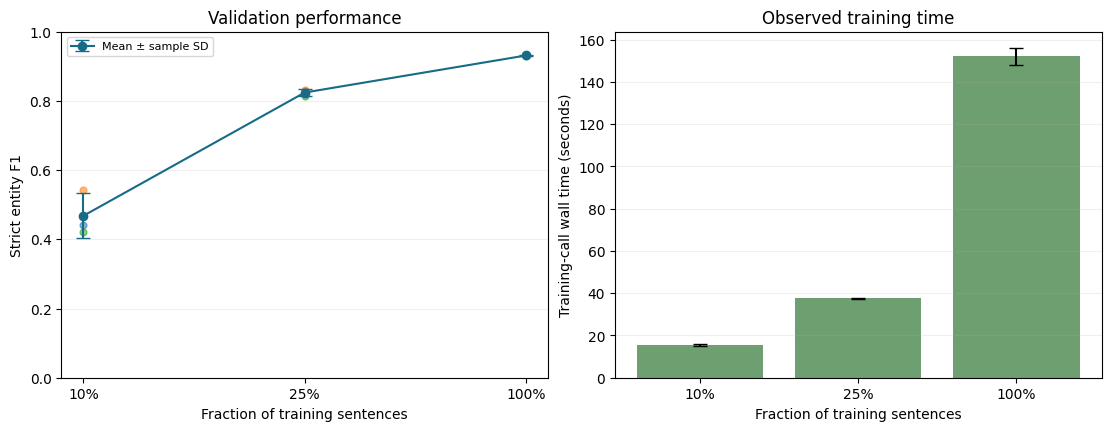

In [12]:
if RUN_TRAINING:
    assert len(validation_records) == len(FRACTIONS) * len(SEEDS)
    comparison = pd.DataFrame([{"fraction_percent": r["fraction_percent"], "seed": r["seed"],
                               "training_sentences": r["n_training_sentences"],
                               "entity_precision": r["metrics"]["precision"],
                               "entity_recall": r["metrics"]["recall"],
                               "entity_f1": r["metrics"]["f1"],
                               "word_accuracy": r["metrics"]["word_accuracy"],
                               "training_seconds": r["training_seconds"],
                               "optimizer_steps": r["optimizer_steps"]} for r in validation_records])
    comparison = comparison.sort_values(["fraction_percent", "seed"]).reset_index(drop=True)
    summary = comparison.groupby("fraction_percent").agg(
        training_sentences=("training_sentences", "first"),
        entity_f1_mean=("entity_f1", "mean"), entity_f1_sd=("entity_f1", "std"),
        precision_mean=("entity_precision", "mean"), recall_mean=("entity_recall", "mean"),
        training_seconds_mean=("training_seconds", "mean"), training_seconds_sd=("training_seconds", "std"))
    comparison.to_csv(ARTIFACTS / "validation_comparison.csv", index=False)
    summary.to_csv(ARTIFACTS / "validation_summary.csv")
    display(comparison.round(4))
    display(summary.round(4))
    # Compare each seed with itself when calculating data-size gains.
    paired = comparison.pivot(index="seed", columns="fraction_percent", values="entity_f1")
    paired_gains = pd.DataFrame({"100_minus_10_f1": paired[100] - paired[10],
                                "100_minus_25_f1": paired[100] - paired[25]})
    paired_gains.to_csv(ARTIFACTS / "paired_validation_gains.csv")
    display(paired_gains.round(4))
    # Use a fixed 0-to-1 F1 axis and show all individual runs alongside mean/SD.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
    x = np.arange(len(summary))
    axes[0].errorbar(x, summary.entity_f1_mean, yerr=summary.entity_f1_sd,
                    fmt="o-", capsize=5, color="#176b87", label="Mean ± sample SD")
    for seed, group in comparison.groupby("seed"):
        axes[0].scatter(x, group.entity_f1, s=24, alpha=0.55)
    axes[0].set(ylabel="Strict entity F1", ylim=(0, 1), title="Validation performance")
    axes[0].legend(fontsize=8)
    axes[1].bar(x, summary.training_seconds_mean, yerr=summary.training_seconds_sd,
                capsize=5, color="#6d9f71")
    axes[1].set(ylabel="Training-call wall time (seconds)", title="Observed training time")
    for axis in axes:
        axis.set_xticks(x, [f"{f}%" for f in summary.index])
        axis.set_xlabel("Fraction of training sentences")
        axis.grid(axis="y", alpha=0.2)
    fig.savefig(ARTIFACTS / "data_efficiency.png", dpi=180)
    fig.savefig(ARTIFACTS / "data_efficiency.svg")
    plt.show()


## 9. Select the fraction and inspect validation errors

Selection uses mean validation F1 across seeds. The per-type table and worksheet describe the selected fraction's prespecified seed-42 model, which will also be used for the final test. Review these separately from the three-seed average.

When interpreting mistakes, distinguish missing entities, wrong types, and boundaries that include too few or too many words. A few examples can suggest hypotheses; they do not identify the model's internal cause or establish a general failure rate.


In [13]:
if RUN_TRAINING:
    selected_fraction, means = choose_fraction(validation_records)
    selected_key = f"p{selected_fraction}_s{TEST_SEED}"
    selected_record = next(r for r in validation_records
                           if r["fraction_percent"] == selected_fraction and r["seed"] == TEST_SEED)
    selection = {"fraction_percent": selected_fraction, "seed": TEST_SEED,
                 "mean_validation_f1": {str(k): v for k, v in means.items()},
                 "rule": config["selection_rule"], "test_rule": config["test_rule"],
                 "checkpoint_weight_sha256": selected_record["checkpoint_weight_sha256"]}
    write_json(ARTIFACTS / "selection.json", selection)
    print(json.dumps(selection, indent=2))
    display(pd.DataFrame(selected_record["metrics"]["per_type"]).T.round(4))
    # Save only row IDs, spans, categories, and numerical scores in the worksheet.
    with np.load(ARTIFACTS / f"validation_{selected_key}.npz", allow_pickle=False) as saved:
        error_candidates = pd.DataFrame(error_rows(saved), columns=["validation_row_id", "error_kind", "entity_type",
                                                                   "start_word", "end_word_exclusive",
                                                                   "mean_predicted_token_score", "my_observation"])
    error_candidates.to_csv(ARTIFACTS / "validation_error_review.csv", index=False)
    display(error_candidates.head(10))


{
  "fraction_percent": 100,
  "seed": 42,
  "mean_validation_f1": {
    "10": 0.4679391410193641,
    "25": 0.8240658776037274,
    "100": 0.9311945514201586
  },
  "rule": "highest mean validation strict entity F1; exact tie uses smaller fraction",
  "test_rule": "one checkpoint from chosen fraction using the first prespecified seed",
  "checkpoint_weight_sha256": "1036d0845ef76560caf33d163abffdb33d517b89925881e6db5b6a6c044e8146"
}


,tp,fp,fn,gold_entities,predicted_entities,precision,recall,f1
LOC,1731.0,66.0,106.0,1837.0,1797.0,0.9633,0.9423,0.9527
MISC,781.0,139.0,141.0,922.0,920.0,0.8489,0.8471,0.8480
ORG,1203.0,103.0,138.0,1341.0,1306.0,0.9211,0.8971,0.9090
PER,1802.0,78.0,40.0,1842.0,1880.0,0.9585,0.9783,0.9683


,validation_row_id,error_kind,entity_type,start_word,end_word_exclusive,mean_predicted_token_score,my_observation
0,2881,missed_gold_entity,MISC,2,3,0.999699,
1,3063,missed_gold_entity,MISC,4,5,0.999560,
2,14,missed_gold_entity,MISC,12,13,0.999342,
3,2630,missed_gold_entity,MISC,2,3,0.999291,
4,584,missed_gold_entity,MISC,12,13,0.999205,
5,756,missed_gold_entity,ORG,19,21,0.997921,
6,2624,missed_gold_entity,MISC,8,9,0.997649,
7,2858,missed_gold_entity,MISC,34,35,0.997591,
8,2911,extra_predicted_entity,LOC,0,1,0.997558,
9,2911,missed_gold_entity,PER,0,1,0.997558,


### Optional: display one chosen validation sentence

After the run, set `SHOW_REVIEW_TEXT = True` and `REVIEW_ROW_ID` to a row from the worksheet, then rerun only this cell. The training data and selection do not change. Add your interpretation to the worksheet before final packaging. Keep this display disabled when producing a text-free public output copy.


In [14]:
# Choose a row deliberately when conducting qualitative review.
SHOW_REVIEW_TEXT = False
REVIEW_ROW_ID = None
if SHOW_REVIEW_TEXT:
    if not isinstance(REVIEW_ROW_ID, int) or not 0 <= REVIEW_ROW_ID < len(dataset["validation"]):
        raise ValueError("Choose a valid validation_row_id from the error worksheet.")
    with np.load(ARTIFACTS / f"validation_{selected_key}.npz", allow_pickle=False) as saved:
        gold, predicted = sequences_from_arrays(saved)
    display(pd.DataFrame({"word": dataset["validation"][REVIEW_ROW_ID]["tokens"],
                          "actual": gold[REVIEW_ROW_ID], "predicted": predicted[REVIEW_ROW_ID]}))


## 10. Evaluate the selected model on the test split

The chosen fraction and fixed test seed were recorded above. The test result is reported for that single checkpoint; it is **not** a three-seed test average. Test labels are used here for scoring and do not choose the model. Do not change the experiment in response to test errors and then describe the same test as a fresh holdout.

Both test predictions and all class scores are saved, so final-test metrics can be independently recalculated.


In [15]:
if RUN_TRAINING and RUN_FINAL_TEST:
    # Re-running this cell displays the existing result instead of silently testing again.
    if (ARTIFACTS / "final_test_metrics.json").exists():
        final_test = json.loads((ARTIFACTS / "final_test_metrics.json").read_text())
    else:
        checkpoint = CHECKPOINTS / selected_key
        assert hashlib.sha256((checkpoint / "model.safetensors").read_bytes()).hexdigest() == selection["checkpoint_weight_sha256"]
        test_inputs = dataset["test"].map(lambda batch: align_first_subword(batch, tokenizer, MAX_LENGTH),
                                          batched=True, remove_columns=dataset["test"].column_names)
        model = AutoModelForTokenClassification.from_pretrained(str(checkpoint), use_safetensors=True)
        test_args = TrainingArguments(output_dir=str(CHECKPOINTS / "test_evaluation"),
                                      per_device_eval_batch_size=BATCH_SIZE, report_to="none",
                                      fp16=False, bf16=False, eval_accumulation_steps=10)
        test_trainer = Trainer(model=model, args=test_args, processing_class=tokenizer, data_collator=data_collator)
        test_metrics, test_arrays = evaluate_predictions(test_trainer, "test", test_inputs, "final_test_predictions.npz")
        final_test = {"fraction_percent": selected_fraction, "seed": TEST_SEED,
                      "split": "test", "metrics": test_metrics}
        write_json(ARTIFACTS / "final_test_metrics.json", final_test)
        del test_arrays, test_trainer, model
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    print(json.dumps(final_test, indent=2))
    display(pd.DataFrame(final_test["metrics"]["per_type"]).T.round(4))
else:
    print("Final test evaluation was not run.")


{
  "fraction_percent": 100,
  "seed": 42,
  "split": "test",
  "metrics": {
    "tp": 5104,
    "fp": 552,
    "fn": 544,
    "gold_entities": 5648,
    "predicted_entities": 5656,
    "precision": 0.9024045261669024,
    "recall": 0.9036827195467422,
    "f1": 0.9030431705590941,
    "n_sentences": 3453,
    "n_words": 46435,
    "word_accuracy": 0.9800796812749004,
    "invalid_predicted_i_transitions": 94,
    "per_type": {
      "LOC": {
        "tp": 1534,
        "fp": 124,
        "fn": 134,
        "gold_entities": 1668,
        "predicted_entities": 1658,
        "precision": 0.9252110977080821,
        "recall": 0.919664268585132,
        "f1": 0.9224293445580276
      },
      "MISC": {
        "tp": 558,
        "fp": 188,
        "fn": 144,
        "gold_entities": 702,
        "predicted_entities": 746,
        "precision": 0.7479892761394102,
        "recall": 0.7948717948717948,
        "f1": 0.7707182320441989
      },
      "ORG": {
        "tp": 1459,
        "fp": 

,tp,fp,fn,gold_entities,predicted_entities,precision,recall,f1
LOC,1534.0,124.0,134.0,1668.0,1658.0,0.9252,0.9197,0.9224
MISC,558.0,188.0,144.0,702.0,746.0,0.7480,0.7949,0.7707
ORG,1459.0,170.0,202.0,1661.0,1629.0,0.8956,0.8784,0.8869
PER,1553.0,70.0,64.0,1617.0,1623.0,0.9569,0.9604,0.9586


## 11. Verify saved predictions and export the results

This check reloads all saved prediction files and recomputes the entity metrics. The ZIP includes configuration, revisions, actual package versions, indices, metrics, predictions, figures, and the error worksheet. It excludes raw sentences and large model checkpoints.

The companion project package also contains `scripts/verify_results.py`, which verifies the results independently without a GPU. After downloading, retain both the ZIP and this notebook with its executed outputs.


In [16]:
if RUN_TRAINING:
    # Check that the saved evidence reproduces every validation score.
    for record in validation_records:
        key = f"p{record['fraction_percent']}_s{record['seed']}"
        with np.load(ARTIFACTS / f"validation_{key}.npz", allow_pickle=False) as saved:
            assert metrics_from_arrays(saved) == record["metrics"]
    # Also verify the saved final test predictions when final evaluation ran.
    if RUN_FINAL_TEST:
        with np.load(ARTIFACTS / "final_test_predictions.npz", allow_pickle=False) as saved:
            assert metrics_from_arrays(saved) == final_test["metrics"]
    write_json(ARTIFACTS / "prediction_recheck.json", {"status": "passed", "validation_runs": len(validation_records),
               "final_test_verified": bool(RUN_FINAL_TEST), "method": "reload NPZ and recalculate strict entity metrics"})
    build_manifest(ARTIFACTS)
    # Archive the result directory with its unique run name.
    archive = shutil.make_archive(str(ARTIFACTS), "zip", root_dir=ARTIFACTS.parent, base_dir=ARTIFACTS.name)
    print("Saved results:", archive)
    # Colab downloads the completed ZIP to your computer.
    try:
        from google.colab import files
        files.download(archive)
    except ImportError:
        print("Outside Colab: download the ZIP from the notebook's file browser.")


Saved results: /content/artifacts/ner_20261117T193146Z-d76812.zip


## 12. Interpretation of the recorded run

## Selected validation errors

Five validation rows were reviewed after numerical verification. These examples were chosen to illustrate distinct disagreements, not sampled to estimate how common each cause is. Their observations are in [analysis/error_analysis.csv](analysis/error_analysis.csv). The original 811-row error worksheet remains unchanged.

- **Row 2653 — partial boundary:** the reference entity includes “The” in “The Netherlands,” while the model starts at “Netherlands.” The type is correct, but strict scoring requires the complete span.
- **Row 14 — missed modifier:** a hyphenated descriptor is labeled MISC but predicted as non-entity. Person names in the same sentence are recognized.
- **Row 756 — organization and label transition:** a lower-case organization phrase is missed, and a separate person-name token receives an invalid continuation tag after punctuation. These are observable errors; their internal causes are not established.
- **Rows 2911 and 2881 — possible reference ambiguity:** a dateline-like item is labeled PER but predicted LOC, and an ordinary noun is labeled MISC but predicted non-entity. Both merit annotation review. No ground-truth labels were changed, and these examples do not establish that the reference annotations are wrong.

The worksheet's score is the mean of maximum word-level softmax scores across the listed span. A missed entity can have a high score because the model strongly predicts `O`. It is not a calibrated probability that a complete entity is correct. The test predictions contain 94 invalid `I` transitions, which strict BIO2 scoring does not silently repair.

## Method and trade-offs

- **Data and model:** CoNLL-2003 from `lhoestq/conll2003`, using 14,041 training, 3,250 validation, and 3,453 test sentences; `google-bert/bert-base-cased` with a newly initialized nine-label token classifier. Both source revisions are fixed and recorded.
- **Comparison:** nested 10%, 25%, and 100% sentence samples within each of seeds 42, 43, and 44. Every run starts from the pretrained model, and initial classifier hashes match across fractions within each seed. All model parameters are trained.
- **Training:** one epoch, batch size 16, learning rate 0.00002, weight decay 0.01, linear schedule, no warmup, float32. The recorded numbers of optimizer steps are 88, 220, and 878 for the respective fractions.
- **Scoring:** one label per original word, sentence boundaries retained, strict IOB2 exact entity matches, and per-type counts. Continuation subwords and special/padding tokens are ignored with `-100`. Inputs are not silently truncated.
- **Selection:** highest mean validation entity F1, with smaller fraction as the exact-tie rule. Seed 42 was fixed in advance for the selected fraction's final test; the highest-scoring seed was not chosen after observing results.

One epoch gives larger samples more optimizer updates. The comparison therefore measures data size together with its one-epoch training budget, not the isolated causal effect of additional data at equal compute. Hyperparameters were not tuned separately for the fractions. Three seeds describe limited variation; no confidence interval or significance claim is made.

The official splits were preserved. The exact-sentence audit found **130** normalized unique sentences shared by train/validation, **78** by train/test, and **26** by validation/test. Within-split duplicate-row counts were **1,360**, **182**, and **273**, respectively. These are exact-text counts, not counts of duplicate entities or an audit of semantic duplicates or pretraining exposure. They limit a claim that every evaluation sentence is wholly unseen.

Softmax scores are uncalibrated. News-domain performance does not establish performance on policy, maritime, or operational documents. No independent annotation reliability study was conducted.

### Sources
- Alammar, J., & Grootendorst, M. (2024). *Hands-On Large Language Models*, [Chapter 11 code](https://github.com/HandsOnLLM/Hands-On-Large-Language-Models/tree/main/chapter11), Apache-2.0.
- [BERT base cased model card](https://huggingface.co/google-bert/bert-base-cased).
- [CoNLL-2003 dataset repository](https://huggingface.co/datasets/lhoestq/conll2003) and [original shared task](https://aclanthology.org/W03-0419/).
- [Hugging Face token-classification documentation](https://huggingface.co/docs/transformers/en/tasks/token_classification).
- [seqeval strict-mode documentation](https://github.com/chakki-works/seqeval).

The code license does not grant rights to the dataset or model. Corpus text and checkpoints are not bundled with this project package.
